In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
month_close_cap_return = pd.read_csv('TRD_Mnth.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Trdmnt','Mclsprc','Msmvosd','Mretnd']
new_name = ['Stkcd', 'Trdmnt','close','market_cap','return']
month_close_cap_return = month_close_cap_return[columns]
month_close_cap_return.columns = new_name
month_close_cap_return['Trdmnt'] = pd.to_datetime(month_close_cap_return['Trdmnt'], format='%Y-%m') + pd.offsets.MonthEnd(0)
month_close_cap_return

,Stkcd,Trdmnt,close,market_cap,return
0,000001,2009-12-31,24.37,71260664.59,0.004534
1,000001,2010-01-31,21.70,63453279.51,-0.109561
2,000001,2010-02-28,22.45,65646365.20,0.034562
3,000001,2010-03-31,23.20,67839450.90,0.033408
4,000001,2010-04-30,20.56,60119789.25,-0.113793
...,...,...,...,...,...
606577,873833,2024-08-31,7.54,239224.10,-0.074847
606578,873833,2024-09-30,9.86,312831.51,0.307692
606579,873833,2024-10-31,12.94,410551.70,0.327586
606580,873833,2024-11-30,17.31,549200.15,0.337713


In [9]:
nps= pd.read_csv('FI_T9.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Accper','Typrep','F091002A']
nps =nps[columns]
nps = nps[nps['Typrep'] == 'A']
nps['NPS'] = nps['F091002A']
nps.drop(columns=['Typrep', 'F091002A'], inplace=True)

roe = pd.read_csv('FI_T5.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Accper','Typrep','F050504C']
roe =roe[columns]
roe = roe[roe['Typrep'] == 'A']
roe['ROE'] = roe['F050504C']
roe.drop(columns=['Typrep', 'F050504C'], inplace=True)

quarter_roe_nps = pd.merge(nps, roe, on=['Stkcd', 'Accper'])
quarter_roe_nps

asset_lia = pd.read_csv('FS_Combas.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Accper','Typrep','A001000000','A002000000']
asset_lia=asset_lia[columns]
asset_lia = asset_lia[asset_lia['Typrep'] == 'A']
asset_lia['total_asset'] =asset_lia['A001000000']
asset_lia['total_liability'] =asset_lia['A002000000']
asset_lia.drop(columns=['Typrep', 'A001000000', 'A002000000'], inplace=True)

quarter_data = pd.merge(quarter_roe_nps, asset_lia, on=['Stkcd', 'Accper'])

In [10]:
quarter_data

,Stkcd,Accper,NPS,ROE,total_asset,total_liability
0,000001,2009-09-30,6.146785,0.049887,5.542647e+11,5.351762e+11
1,000001,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11
2,000001,2010-03-31,7.119722,0.280066,6.199276e+11,5.978178e+11
3,000001,2010-06-30,8.729121,0.237663,6.243982e+11,5.939771e+11
4,000001,2010-09-30,9.223532,0.239194,6.750639e+11,6.429197e+11
...,...,...,...,...,...,...
210316,873833,2023-06-30,NaN,0.112565,7.027849e+08,1.995230e+08
210317,873833,2023-12-31,7.681109,0.076357,7.787256e+08,1.461094e+08
210318,873833,2024-03-31,7.754442,0.070058,7.523273e+08,1.136714e+08
210319,873833,2024-06-30,7.498464,0.053649,7.340608e+08,1.164873e+08


In [36]:
daily_vola = pd.read_csv('STK_MKT_STKBTAL.csv',dtype={'Symbol': str})

In [ ]:
quarter_data['Accper'] = pd.to_datetime(quarter_data['Accper']) 
month_close_cap_return.set_index('Stkcd', inplace=True)
quarter_data.set_index('Stkcd', inplace=True)

In [16]:
#combine monthly and quarterly data
def get_latest_quarter_date(group, quarter_data):
    # 筛选出相同股票代码的季度数据
    stock_data = quarter_data[quarter_data.index == group.name]
    
    # 找到该月之前最近的季度日期
    latest_quarters = []
    for row in group.itertuples():
        
        latest_quarter = stock_data[stock_data['Accper'] <= getattr(row, 'Trdmnt')].sort_values('Accper', ascending=False).head(1)
        
        if not latest_quarter.empty:
            latest_quarters.append(latest_quarter['Accper'].iloc[0])
        else:
            latest_quarters.append(pd.NaT)
    
    group['latest_quarter_date'] = latest_quarters
    return group

month_merged =month_close_cap_return.groupby(month_close_cap_return.index).apply(lambda group: get_latest_quarter_date(group, quarter_data))


In [18]:
month_merged = month_merged.droplevel(level=0)
month_merged.reset_index(inplace= True)
month_merged

,Stkcd,Trdmnt,close,market_cap,return,latest_quarter_date
0,000001,2009-12-31,24.37,71260664.59,0.004534,2009-12-31
1,000001,2010-01-31,21.70,63453279.51,-0.109561,2009-12-31
2,000001,2010-02-28,22.45,65646365.20,0.034562,2009-12-31
3,000001,2010-03-31,23.20,67839450.90,0.033408,2010-03-31
4,000001,2010-04-30,20.56,60119789.25,-0.113793,2010-03-31
...,...,...,...,...,...,...
606577,873833,2024-08-31,7.54,239224.10,-0.074847,2024-06-30
606578,873833,2024-09-30,9.86,312831.51,0.307692,2024-09-30
606579,873833,2024-10-31,12.94,410551.70,0.327586,2024-09-30
606580,873833,2024-11-30,17.31,549200.15,0.337713,2024-09-30


In [19]:
df= pd.merge(month_merged, quarter_data, how='left', left_on=['Stkcd', 'latest_quarter_date'], right_on=['Stkcd', 'Accper'])
df

,Stkcd,Trdmnt,close,market_cap,return,latest_quarter_date,Accper,NPS,ROE,total_asset,total_liability
0,000001,2009-12-31,24.37,71260664.59,0.004534,2009-12-31,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11
1,000001,2010-01-31,21.70,63453279.51,-0.109561,2009-12-31,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11
2,000001,2010-02-28,22.45,65646365.20,0.034562,2009-12-31,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11
3,000001,2010-03-31,23.20,67839450.90,0.033408,2010-03-31,2010-03-31,7.119722,0.280066,6.199276e+11,5.978178e+11
4,000001,2010-04-30,20.56,60119789.25,-0.113793,2010-03-31,2010-03-31,7.119722,0.280066,6.199276e+11,5.978178e+11
...,...,...,...,...,...,...,...,...,...,...,...
606577,873833,2024-08-31,7.54,239224.10,-0.074847,2024-06-30,2024-06-30,7.498464,0.053649,7.340608e+08,1.164873e+08
606578,873833,2024-09-30,9.86,312831.51,0.307692,2024-09-30,2024-09-30,7.337831,NaN,7.274720e+08,1.231283e+08
606579,873833,2024-10-31,12.94,410551.70,0.327586,2024-09-30,2024-09-30,7.337831,NaN,7.274720e+08,1.231283e+08
606580,873833,2024-11-30,17.31,549200.15,0.337713,2024-09-30,2024-09-30,7.337831,NaN,7.274720e+08,1.231283e+08


In [20]:
#calculate PB
final_df = df.copy()
final_df.set_index(['Stkcd','Trdmnt'], inplace=True)
total_share = final_df['market_cap']*10**3/final_df['close']
BVPS = (final_df['total_asset'] - final_df['total_liability'])/total_share
final_df['monthly_PB'] = final_df['close']/BVPS
final_df['monthly_PB'] = final_df.apply(
    lambda row: float('nan') if  row['monthly_PB'] == float('inf') else row['monthly_PB'], axis=1
)

In [21]:
final_df

close   market_cap    return latest_quarter_date  \
Stkcd  Trdmnt                                                         
000001 2009-12-31  24.37  71260664.59  0.004534          2009-12-31   
       2010-01-31  21.70  63453279.51 -0.109561          2009-12-31   
       2010-02-28  22.45  65646365.20  0.034562          2009-12-31   
       2010-03-31  23.20  67839450.90  0.033408          2010-03-31   
       2010-04-30  20.56  60119789.25 -0.113793          2010-03-31   
...                  ...          ...       ...                 ...   
873833 2024-08-31   7.54    239224.10 -0.074847          2024-06-30   
       2024-09-30   9.86    312831.51  0.307692          2024-09-30   
       2024-10-31  12.94    410551.70  0.327586          2024-09-30   
       2024-11-30  17.31    549200.15  0.337713          2024-09-30   
       2024-12-31  11.40    361691.61 -0.341421          2024-09-30   

                      Accper       NPS       ROE   total_asset  \
Stkcd  Trdmnt                                                    
000001 2009-12-31 2009-12-31  6.591546  0.272887  5.878110e+11   
       2010-01-31 2009-12-31  6.591546  0.272887  5.878110e+11   
       2010-02-28 2009-12-31  6.591546  0.272887  5.878110e+11   
       2010-03-31 2010-03-31  7.119722  0.280066  6.199276e+11   
       2010-04-30 2010-03-31  7.119722  0.280066  6.199276e+11   
...                      ...       ...       ...           ...   
873833 2024-08-31 2024-06-30  7.498464  0.053649  7.340608e+08   
       2024-09-30 2024-09-30  7.337831       NaN  7.274720e+08   
       2024-10-31 2024-09-30  7.337831       NaN  7.274720e+08   
       2024-11-30 2024-09-30  7.337831       NaN  7.274720e+08   
       2024-12-31 2024-09-30  7.337831       NaN  7.274720e+08   

                   total_liability  monthly_PB  
Stkcd  Trdmnt                                   
000001 2009-12-31     5.673414e+11    3.481291  
       2010-01-31     5.673414e+11    3.099877  
       2010-02-28     5.673414e+11    3.207016  
       2010-03-31     5.978178e+11    3.068294  
       2010-04-30     5.978178e+11    2.719143  
...                            ...         ...  
873833 2024-08-31     1.164873e+08    0.387361  
       2024-09-30     1.231283e+08    0.517638  
       2024-10-31     1.231283e+08    0.679335  
       2024-11-30     1.231283e+08    0.908755  
       2024-12-31     1.231283e+08    0.598487  

[606582 rows x 10 columns]

In [23]:
#delete extreme pb 
def filter_extreme_values(group):
    # 计算当月所有股票的 5% 和 95% 分位数
    pb_5 = group['monthly_PB'].quantile(0.05)
    pb_95 = group['monthly_PB'].quantile(0.95)
    # 只保留 P/B 在 [5%, 95%] 范围内的股票
    return group[(group['monthly_PB'] >= pb_5) & (group['monthly_PB'] <= pb_95)]

final_df = final_df.groupby('Trdmnt').apply(filter_extreme_values)

In [27]:
final_df = final_df .droplevel(level=0)
final_df

,,close,market_cap,return,latest_quarter_date,Accper,NPS,ROE,total_asset,total_liability,monthly_PB
Stkcd,Trdmnt,,,,,,,,,,
000001,2009-12-31,24.37,7.126066e+07,0.004534,2009-12-31,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11,3.481291
000002,2009-12-31,10.81,1.043824e+08,-0.062446,2009-12-31,2009-12-31,4.129845,0.152683,1.376086e+11,9.220004e+10,2.298740
000005,2009-12-31,6.02,5.500733e+06,-0.044444,2009-12-31,2009-12-31,0.768185,-0.067274,1.319204e+09,6.168267e+08,7.831594
000006,2009-12-31,11.33,5.589346e+06,-0.116225,2009-12-31,2009-12-31,4.321826,0.173258,7.272028e+09,5.080070e+09,2.549933
000008,2009-12-31,12.28,6.350689e+05,0.245436,2009-12-31,2009-12-31,0.995560,0.004257,7.940798e+07,6.081754e+06,8.660870
...,...,...,...,...,...,...,...,...,...,...,...
873703,2024-12-31,20.74,6.839024e+05,-0.215879,2024-09-30,2024-09-30,9.737111,0.145504,1.240947e+09,1.926498e+08,0.652394
873706,2024-12-31,12.28,3.151140e+05,-0.312430,2024-09-30,2024-09-30,5.917755,0.121045,7.678069e+08,2.209752e+08,0.576254
873726,2024-12-31,20.78,4.136345e+05,-0.285420,2024-09-30,2024-09-30,6.931924,-0.040505,6.328487e+08,6.389550e+07,0.727010


In [37]:
daily_vola.set_index(['Symbol','TradingDate'], inplace=True)
daily_vola

,,Volatility
Symbol,TradingDate,
000001,2010-12-31,0.375077
000002,2010-12-31,0.360978
000004,2010-12-31,0.382118
000005,2010-12-31,0.409691
000006,2010-12-31,0.502408
...,...,...
601958,2010-12-31,0.517640
601988,2010-12-31,0.201127
601991,2010-12-31,0.285140


#### Q1

In [30]:
df1  = final_df[final_df.index.get_level_values(1) == '2010-12-31'].loc[:,['monthly_PB','ROE']]

# df = pd.merge(daily_vola, df1, left_on=['Symbol','TradingDate'], right_on = ['Stkcd','Trdmnt'], how='left')

In [50]:

daily_vola_reset = daily_vola.reset_index()
df1_reset = df1.reset_index()
daily_vola_reset['TradingDate'] = pd.to_datetime(daily_vola_reset['TradingDate'])
df1_reset['Trdmnt'] = pd.to_datetime(df1_reset['Trdmnt'])
reg_df = pd.merge(
    daily_vola_reset, 
    df1_reset, 
    left_on=['Symbol', 'TradingDate'], 
    right_on=['Stkcd', 'Trdmnt'], 
    how='left'
)
reg_df.drop(columns=['Stkcd', 'Trdmnt'], inplace=True)
reg_df.dropna(inplace=True)
reg_df =reg_df.reset_index(drop=True)
reg_df

,Symbol,TradingDate,Volatility,monthly_PB,ROE
0,000001,2010-12-31,0.375077,1.477026,0.234177
1,000002,2010-12-31,0.360978,1.454809,0.176802
2,000004,2010-12-31,0.382118,7.815436,0.184460
3,000005,2010-12-31,0.409691,4.965737,-0.006426
4,000006,2010-12-31,0.502408,2.018557,0.209026
...,...,...,...,...,...
1414,601958,2010-12-31,0.517640,1.379750,0.062149
1415,601988,2010-12-31,0.201127,0.934032,0.179594
1416,601991,2010-12-31,0.285140,1.345161,0.105288
1417,601998,2010-12-31,0.357737,1.113660,0.188118


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns


X = sm.add_constant(reg_df[['ROE', 'Volatility']])
y = reg_df['monthly_PB']

model = sm.OLS(y, X).fit()

print(model.summary())


# 计算各个变量的相关系数
correlation_matrix = df[['monthly_PB', 'ROE', 'Volatility']].corr()
print("\n相关系数矩阵:")
print(correlation_matrix)





                            OLS Regression Results                            
Dep. Variable:             monthly_PB   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.050
Method:                 Least Squares   F-statistic:                     38.71
Date:                Fri, 14 Mar 2025   Prob (F-statistic):           4.30e-17
Time:                        01:11:23   Log-Likelihood:                -2919.0
No. Observations:                1419   AIC:                             5844.
Df Residuals:                    1416   BIC:                             5860.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5639      0.311      1.811      0.0

#### 第二问

In [55]:
final_df

,,close,market_cap,return,latest_quarter_date,Accper,NPS,ROE,total_asset,total_liability,monthly_PB
Stkcd,Trdmnt,,,,,,,,,,
000001,2009-12-31,24.37,7.126066e+07,0.004534,2009-12-31,2009-12-31,6.591546,0.272887,5.878110e+11,5.673414e+11,3.481291
000002,2009-12-31,10.81,1.043824e+08,-0.062446,2009-12-31,2009-12-31,4.129845,0.152683,1.376086e+11,9.220004e+10,2.298740
000005,2009-12-31,6.02,5.500733e+06,-0.044444,2009-12-31,2009-12-31,0.768185,-0.067274,1.319204e+09,6.168267e+08,7.831594
000006,2009-12-31,11.33,5.589346e+06,-0.116225,2009-12-31,2009-12-31,4.321826,0.173258,7.272028e+09,5.080070e+09,2.549933
000008,2009-12-31,12.28,6.350689e+05,0.245436,2009-12-31,2009-12-31,0.995560,0.004257,7.940798e+07,6.081754e+06,8.660870
...,...,...,...,...,...,...,...,...,...,...,...
873703,2024-12-31,20.74,6.839024e+05,-0.215879,2024-09-30,2024-09-30,9.737111,0.145504,1.240947e+09,1.926498e+08,0.652394
873706,2024-12-31,12.28,3.151140e+05,-0.312430,2024-09-30,2024-09-30,5.917755,0.121045,7.678069e+08,2.209752e+08,0.576254
873726,2024-12-31,20.78,4.136345e+05,-0.285420,2024-09-30,2024-09-30,6.931924,-0.040505,6.328487e+08,6.389550e+07,0.727010


In [56]:
rolling_df = final_df.loc[:,['monthly_PB','return']]
rolling_df

,,monthly_PB,return
Stkcd,Trdmnt,,
000001,2009-12-31,3.481291,0.004534
000002,2009-12-31,2.298740,-0.062446
000005,2009-12-31,7.831594,-0.044444
000006,2009-12-31,2.549933,-0.116225
000008,2009-12-31,8.660870,0.245436
...,...,...,...
873703,2024-12-31,0.652394,-0.215879
873706,2024-12-31,0.576254,-0.312430
873726,2024-12-31,0.727010,-0.285420


In [ ]:
rolling_df = final_df.loc[:,['monthly_PB','return']]
trading_date = rolling_df.index.get_level_values(1).unique()
portfolio_returns = pd.DataFrame()
for i in range(1, len(trading_date)):
    last_month = trading_date[i-1]
    current_month = trading_date[i]

    last_month_data = rolling_df.xs(last_month, level=1)
    last_month_data['decile'] = pd.qcut(last_month_data['monthly_PB'], 10, labels=False)
    current_month_data = rolling_df.xs(current_month, level=1)
    returns = []
    for decile in range(10):
        stocks_in_decile = last_month_data[last_month_data['decile'] == decile].index.tolist()
            
        decile_stocks_returns = current_month_data.loc[current_month_data.index.isin(stocks_in_decile)]

        if not decile_stocks_returns.empty and 'return' in decile_stocks_returns.columns:
                avg_return = decile_stocks_returns['return'].mean()
                returns.append(avg_return)
    portfolio_returns[current_month] = returns    
portfolio_returns = portfolio_returns.T

In [60]:
portfolio_returns 

,0,1,2,3,4,5,6,7,8,9
2010-01-31,-0.048336,-0.048050,-0.036740,-0.024164,-0.032433,-0.018315,-0.028047,-0.029435,-0.039590,-0.037526
2010-02-28,0.056223,0.053226,0.065468,0.067680,0.061722,0.052127,0.079832,0.064982,0.064300,0.056893
2010-03-31,0.052935,0.063038,0.060403,0.049101,0.043909,0.057581,0.035173,0.031818,0.036686,0.025013
2010-04-30,-0.102513,-0.102759,-0.090152,-0.078647,-0.069341,-0.068005,-0.058595,-0.071229,-0.047290,-0.059273
2010-05-31,-0.092593,-0.077005,-0.076807,-0.092969,-0.095283,-0.094287,-0.082533,-0.084492,-0.075861,-0.054869
...,...,...,...,...,...,...,...,...,...,...
2024-08-31,-0.037418,-0.048724,-0.034099,-0.036659,-0.024539,-0.041670,-0.039439,-0.037837,-0.043972,-0.052875
2024-09-30,0.234022,0.229588,0.232873,0.220451,0.231408,0.232018,0.229953,0.239202,0.239198,0.219198
2024-10-31,0.084673,0.088304,0.077058,0.096505,0.072599,0.098487,0.096989,0.086453,0.086642,0.070272
2024-11-30,0.077277,0.071387,0.064702,0.081408,0.076734,0.060292,0.048962,0.034612,0.035228,0.004388


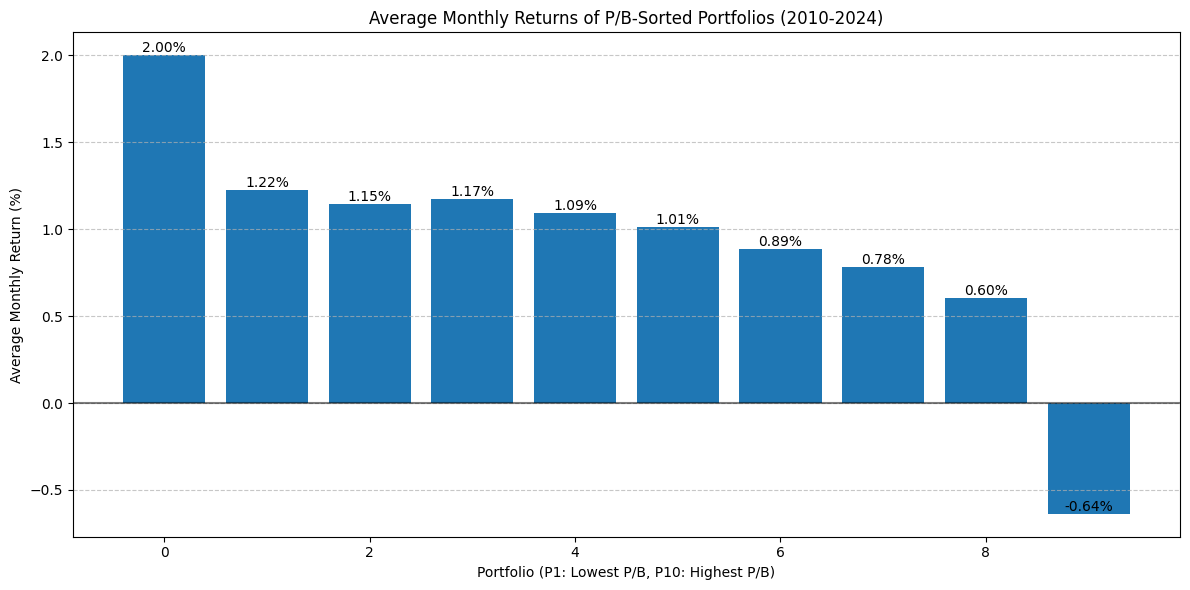

In [61]:
avg_portfolio_returns = portfolio_returns.mean()
plt.figure(figsize=(12, 6))
bars = plt.bar(avg_portfolio_returns.index, avg_portfolio_returns.values * 100)  # 转换为百分比


for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%',
             ha='center', va='bottom')

plt.title('Average Monthly Returns of P/B-Sorted Portfolios (2010-2024)')
plt.xlabel('Portfolio (P1: Lowest P/B, P10: Highest P/B)')
plt.ylabel('Average Monthly Return (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axhline(y=0, color='black', linestyle='-', alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

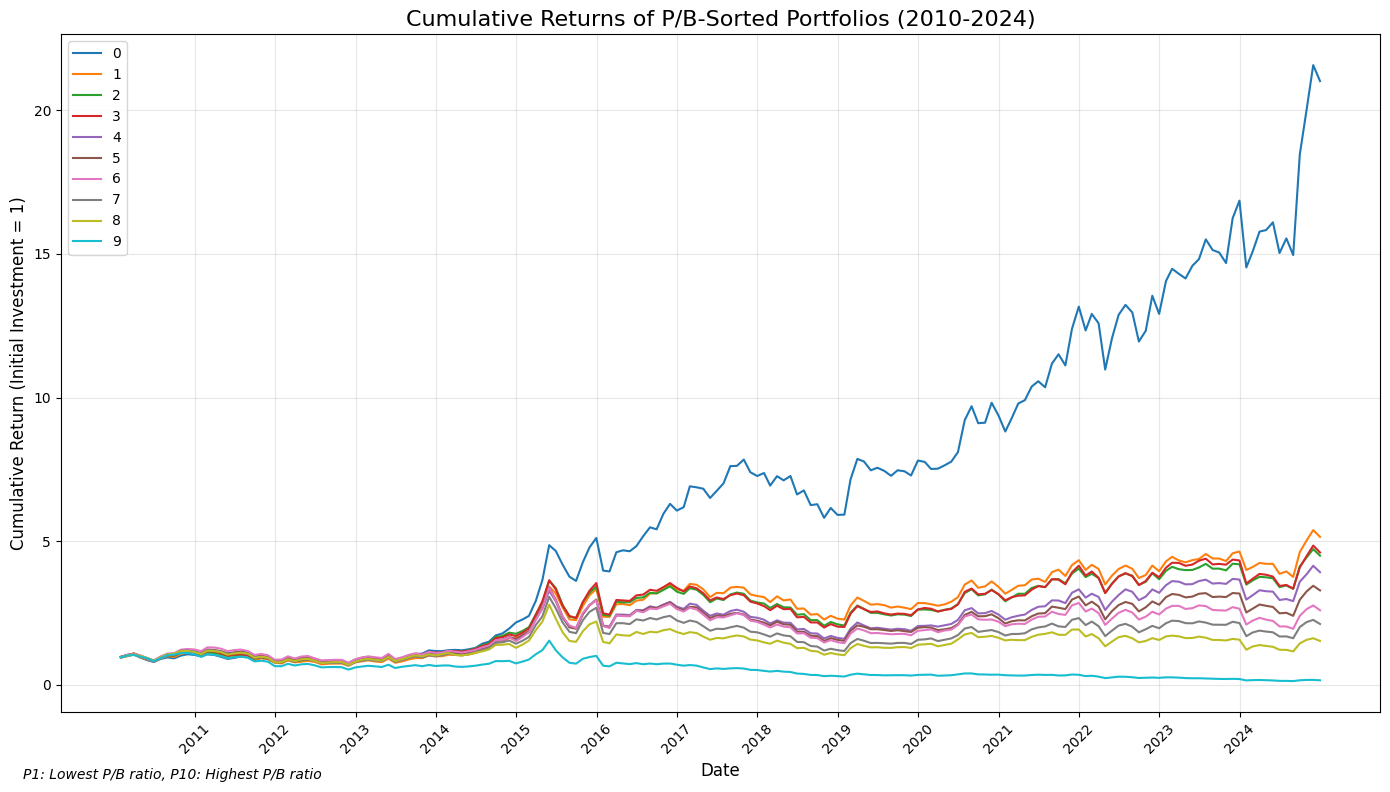

最终累积收益 (初始投资 = 1):
0: 21.0148
1: 5.1529
2: 4.4987
3: 4.6103
4: 3.9246
5: 3.2903
6: 2.6004
7: 2.1210
8: 1.5289
9: 0.1619

年化收益率 (%):
0: 22.51%
1: 11.55%
2: 10.55%
3: 10.73%
4: 9.54%
5: 8.26%
6: 6.58%
7: 5.14%
8: 2.87%
9: -11.43%


In [63]:
# 计算累积收益率
# 从第一个月开始，累积乘积（1 + 月度收益率）
cumulative_returns = (1 + portfolio_returns).cumprod()

# 使用更加可辨别的颜色方案
colors = plt.cm.tab10(np.linspace(0, 1, 10))

# 绘制累积收益率折线图
plt.figure(figsize=(14, 8))

# 遍历每个投资组合并绘制其累积收益率
for i, col in enumerate(cumulative_returns.columns):
    plt.plot(cumulative_returns.index, cumulative_returns[col], 
             label=col, color=colors[i], linewidth=1.5)

# 添加图表标题和标签
plt.title('Cumulative Returns of P/B-Sorted Portfolios (2010-2024)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Cumulative Return (Initial Investment = 1)', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)

# 优化x轴日期显示
plt.xticks(rotation=45)
# 设置适当的时间间隔，例如每年
years = pd.date_range(start=min(cumulative_returns.index), 
                      end=max(cumulative_returns.index), 
                      freq='YS')  # Year Start
plt.xticks(years, [d.strftime('%Y') for d in years])

# 添加图表说明
plt.figtext(0.02, 0.02, 'P1: Lowest P/B ratio, P10: Highest P/B ratio', 
            fontsize=10, style='italic')

plt.tight_layout()
plt.show()

# 打印最终累积收益
final_returns = cumulative_returns.iloc[-1]
print("最终累积收益 (初始投资 = 1):")
for col in cumulative_returns.columns:
    print(f"{col}: {final_returns[col]:.4f}")

# 计算年化收益率
years = len(cumulative_returns) / 12  # 假设是月度数据
annualized_returns = (final_returns ** (1/years) - 1) * 100
print("\n年化收益率 (%):")
for col in cumulative_returns.columns:
    print(f"{col}: {annualized_returns[col]:.2f}%")